In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [3]:
import matplotlib.pyplot as plt
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
!pip install roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 69.3 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


In [5]:
from roboflow import Roboflow
rf = Roboflow(api_key="CFPqVUZkUzpq8L3aQPhe")
project = rf.workspace("noora-alkhalaqi").project("bahraini-currency-1ka60")
version = project.version(2)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bahraini-currency-2 in yolo26:: 100%|██████████| 2155/2155 [00:20<00:00, 107.21it/s] 


# YOLO model

In [6]:
model=YOLO("yolo26s.pt")

In [7]:
result2=model("/content/bahraini-currency-2/valid/images/0_5_0004_jpg.rf.20bc97c7a5c1e806fad9bd0b109e7676.jpg")


image 1/1 /content/bahraini-currency-2/valid/images/0_5_0004_jpg.rf.20bc97c7a5c1e806fad9bd0b109e7676.jpg: 640x320 1 tie, 710.9ms
Speed: 22.8ms preprocess, 710.9ms inference, 30.2ms postprocess per image at shape (1, 3, 640, 320)


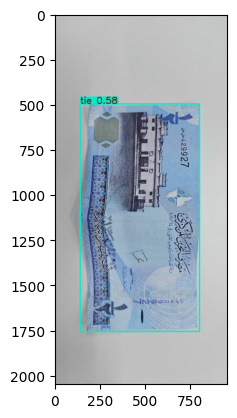

In [8]:
plt.imshow(result2[0].plot())
plt.show()

In [13]:
from numpy import fliplr

In [14]:
model.train(data="/content/bahraini-currency-2/data.yaml", epochs=30, imgsz=224,batch=16, degrees=10, scale=0.2, fliplr=0.5,hsv_v=0.2)

Ultralytics 8.4.198 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bahraini-currency-2/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.2, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a9888ddf9a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0


image 1/1 /content/bahraini-currency-2/train/images/aug_162006_6ccc0324_jpg.rf.d81198c92baf0cb63d0f227a0c12723e.jpg: 128x224 1 5 BD, 67.4ms
Speed: 1.2ms preprocess, 67.4ms inference, 0.9ms postprocess per image at shape (1, 3, 128, 224)


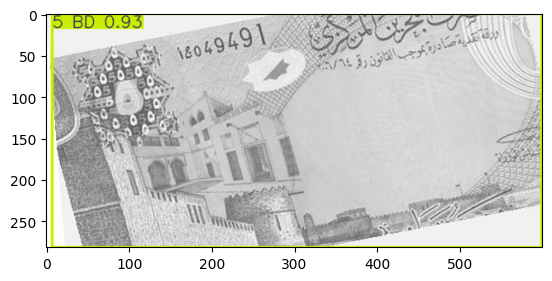

In [15]:
result2=model("/content/bahraini-currency-2/train/images/aug_162006_6ccc0324_jpg.rf.d81198c92baf0cb63d0f227a0c12723e.jpg")
plt.imshow(result2[0].plot()[...,::-1])
plt.show()

In [16]:
import cv2

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    results = model(frame) # prediction
    annotated_frame = results[0].plot()  # draw boxes

    cv2.imshow("YOLO Detection", annotated_frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()


## test set

In [18]:
odel = YOLO("/content/runs/detect/train/weights/best.pt")

In [19]:
metrics= model.val(data="/content/bahraini-currency-2/data.yaml", split="test")

Ultralytics 8.4.198 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 39.4±28.7 MB/s, size: 190.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/bahraini-currency-2/test/labels... 13 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13/13 272.4it/s 0.0s
val: New cache created: /content/bahraini-currency-2/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 12, len(boxes) = 15. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.2s/it

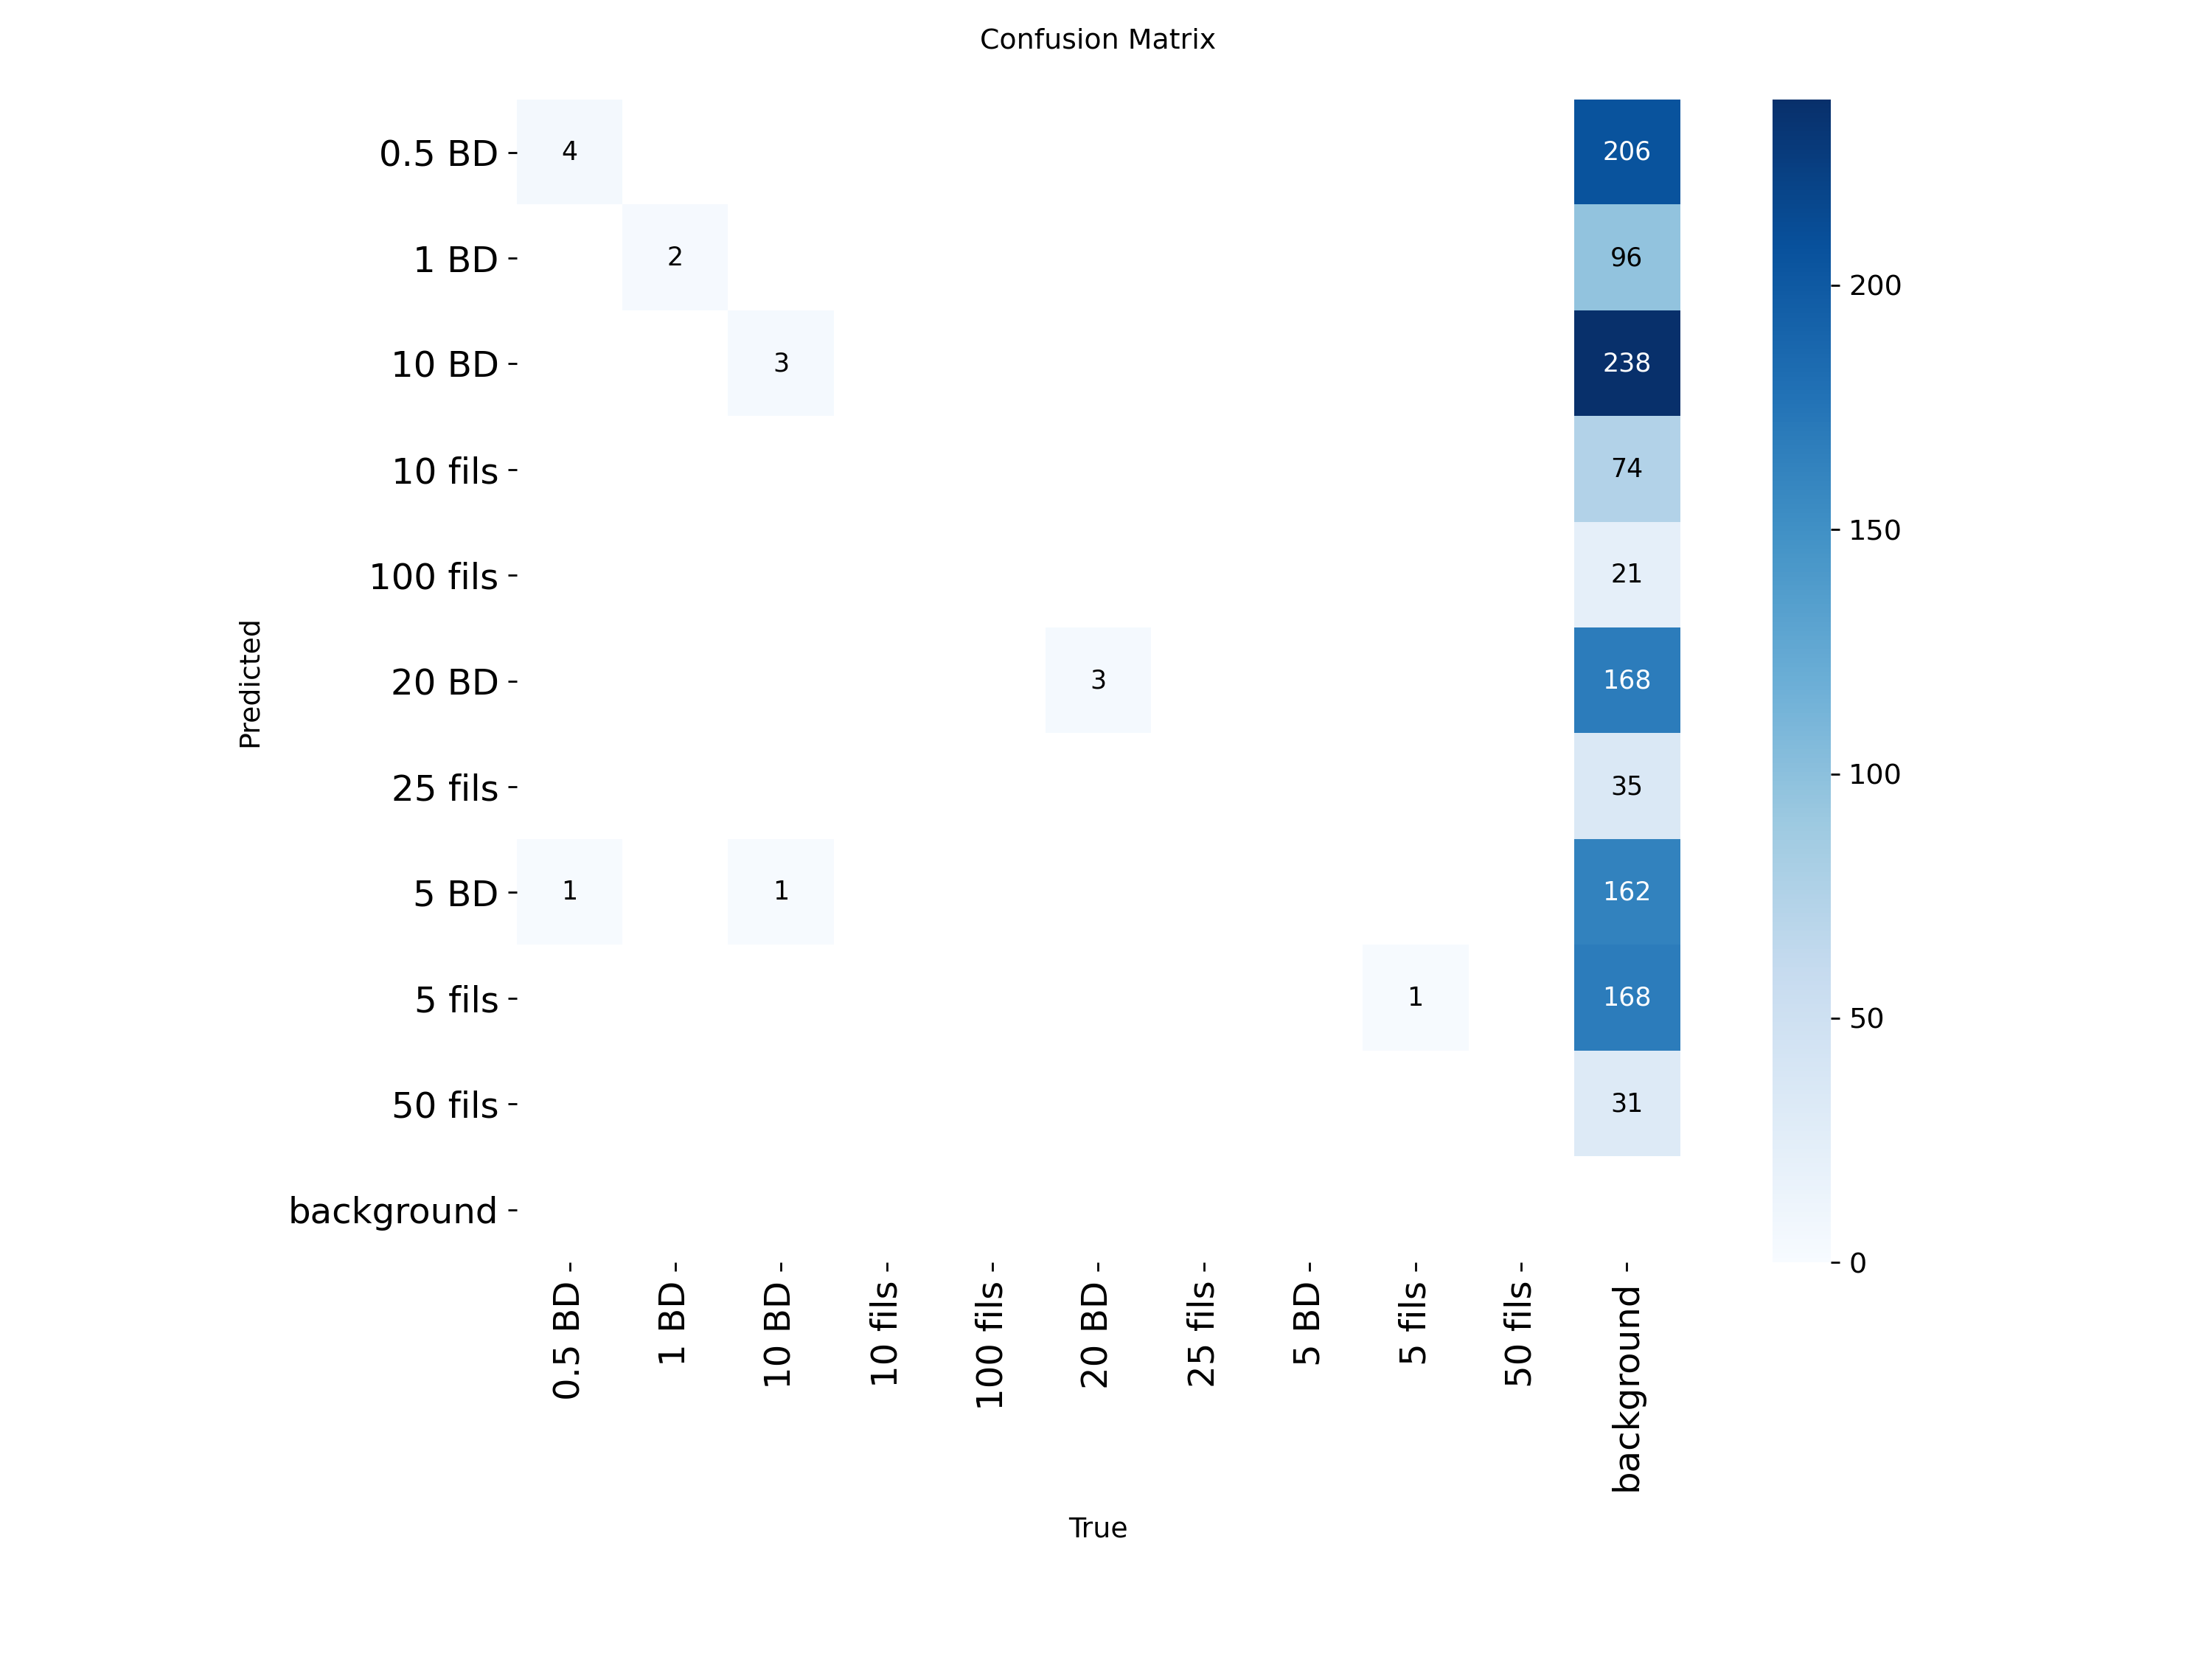

In [20]:
from IPython.display import Image
Image("runs/detect/val/confusion_matrix.png")

In [21]:
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")
# accuracy :
print(f"mAP50: {metrics.box.map50:.4f}")


Precision: 0.9114
Recall: 0.8668
mAP50: 0.8959


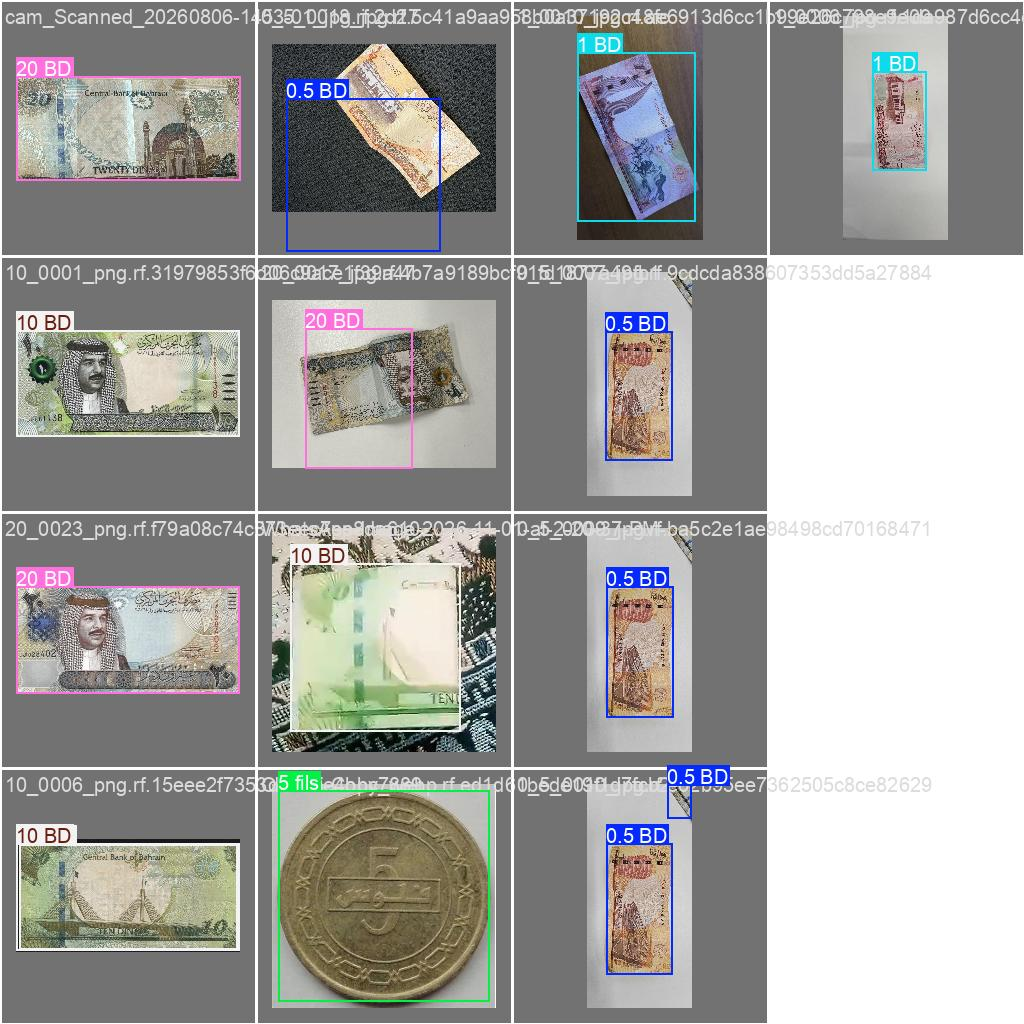

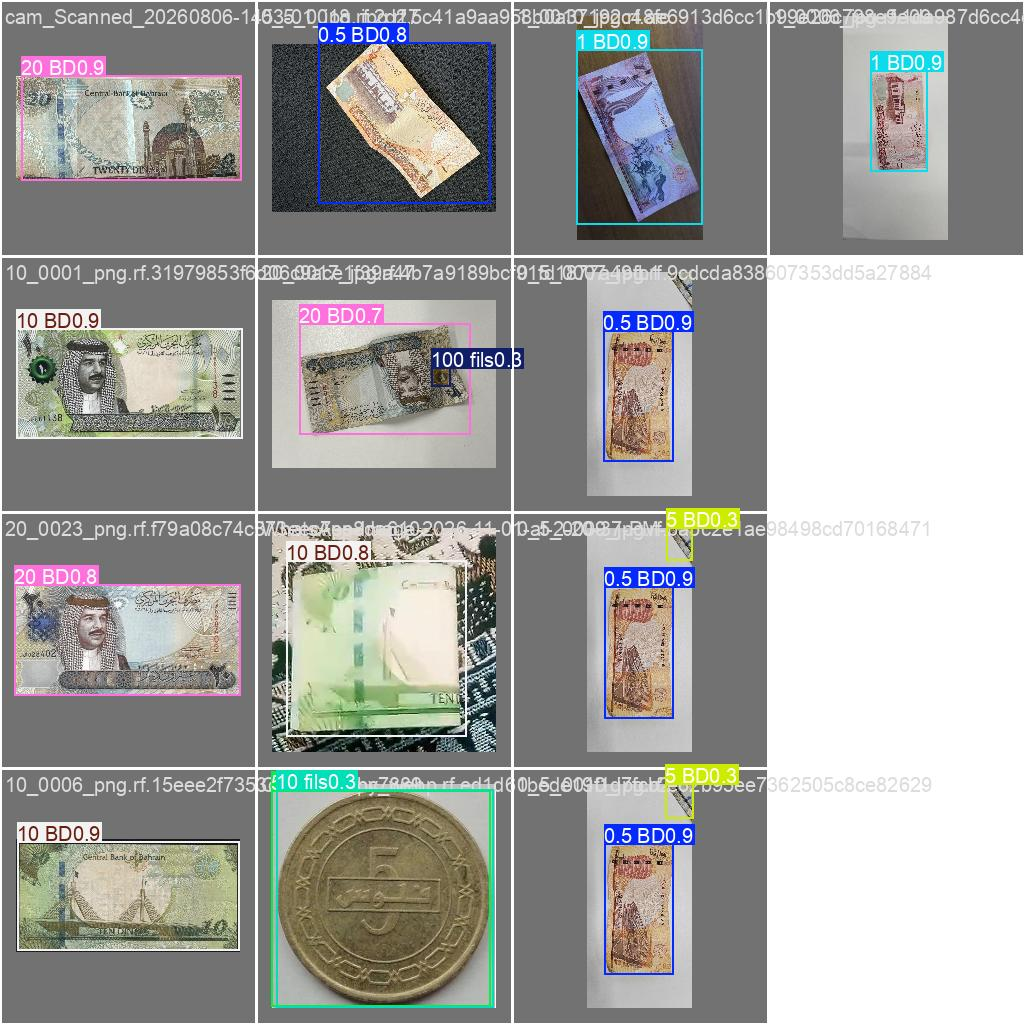

In [22]:
from IPython.display import Image, display
display(Image("runs/detect/val/val_batch0_labels.jpg", width=700))
display(Image("runs/detect/val/val_batch0_pred.jpg", width=700))

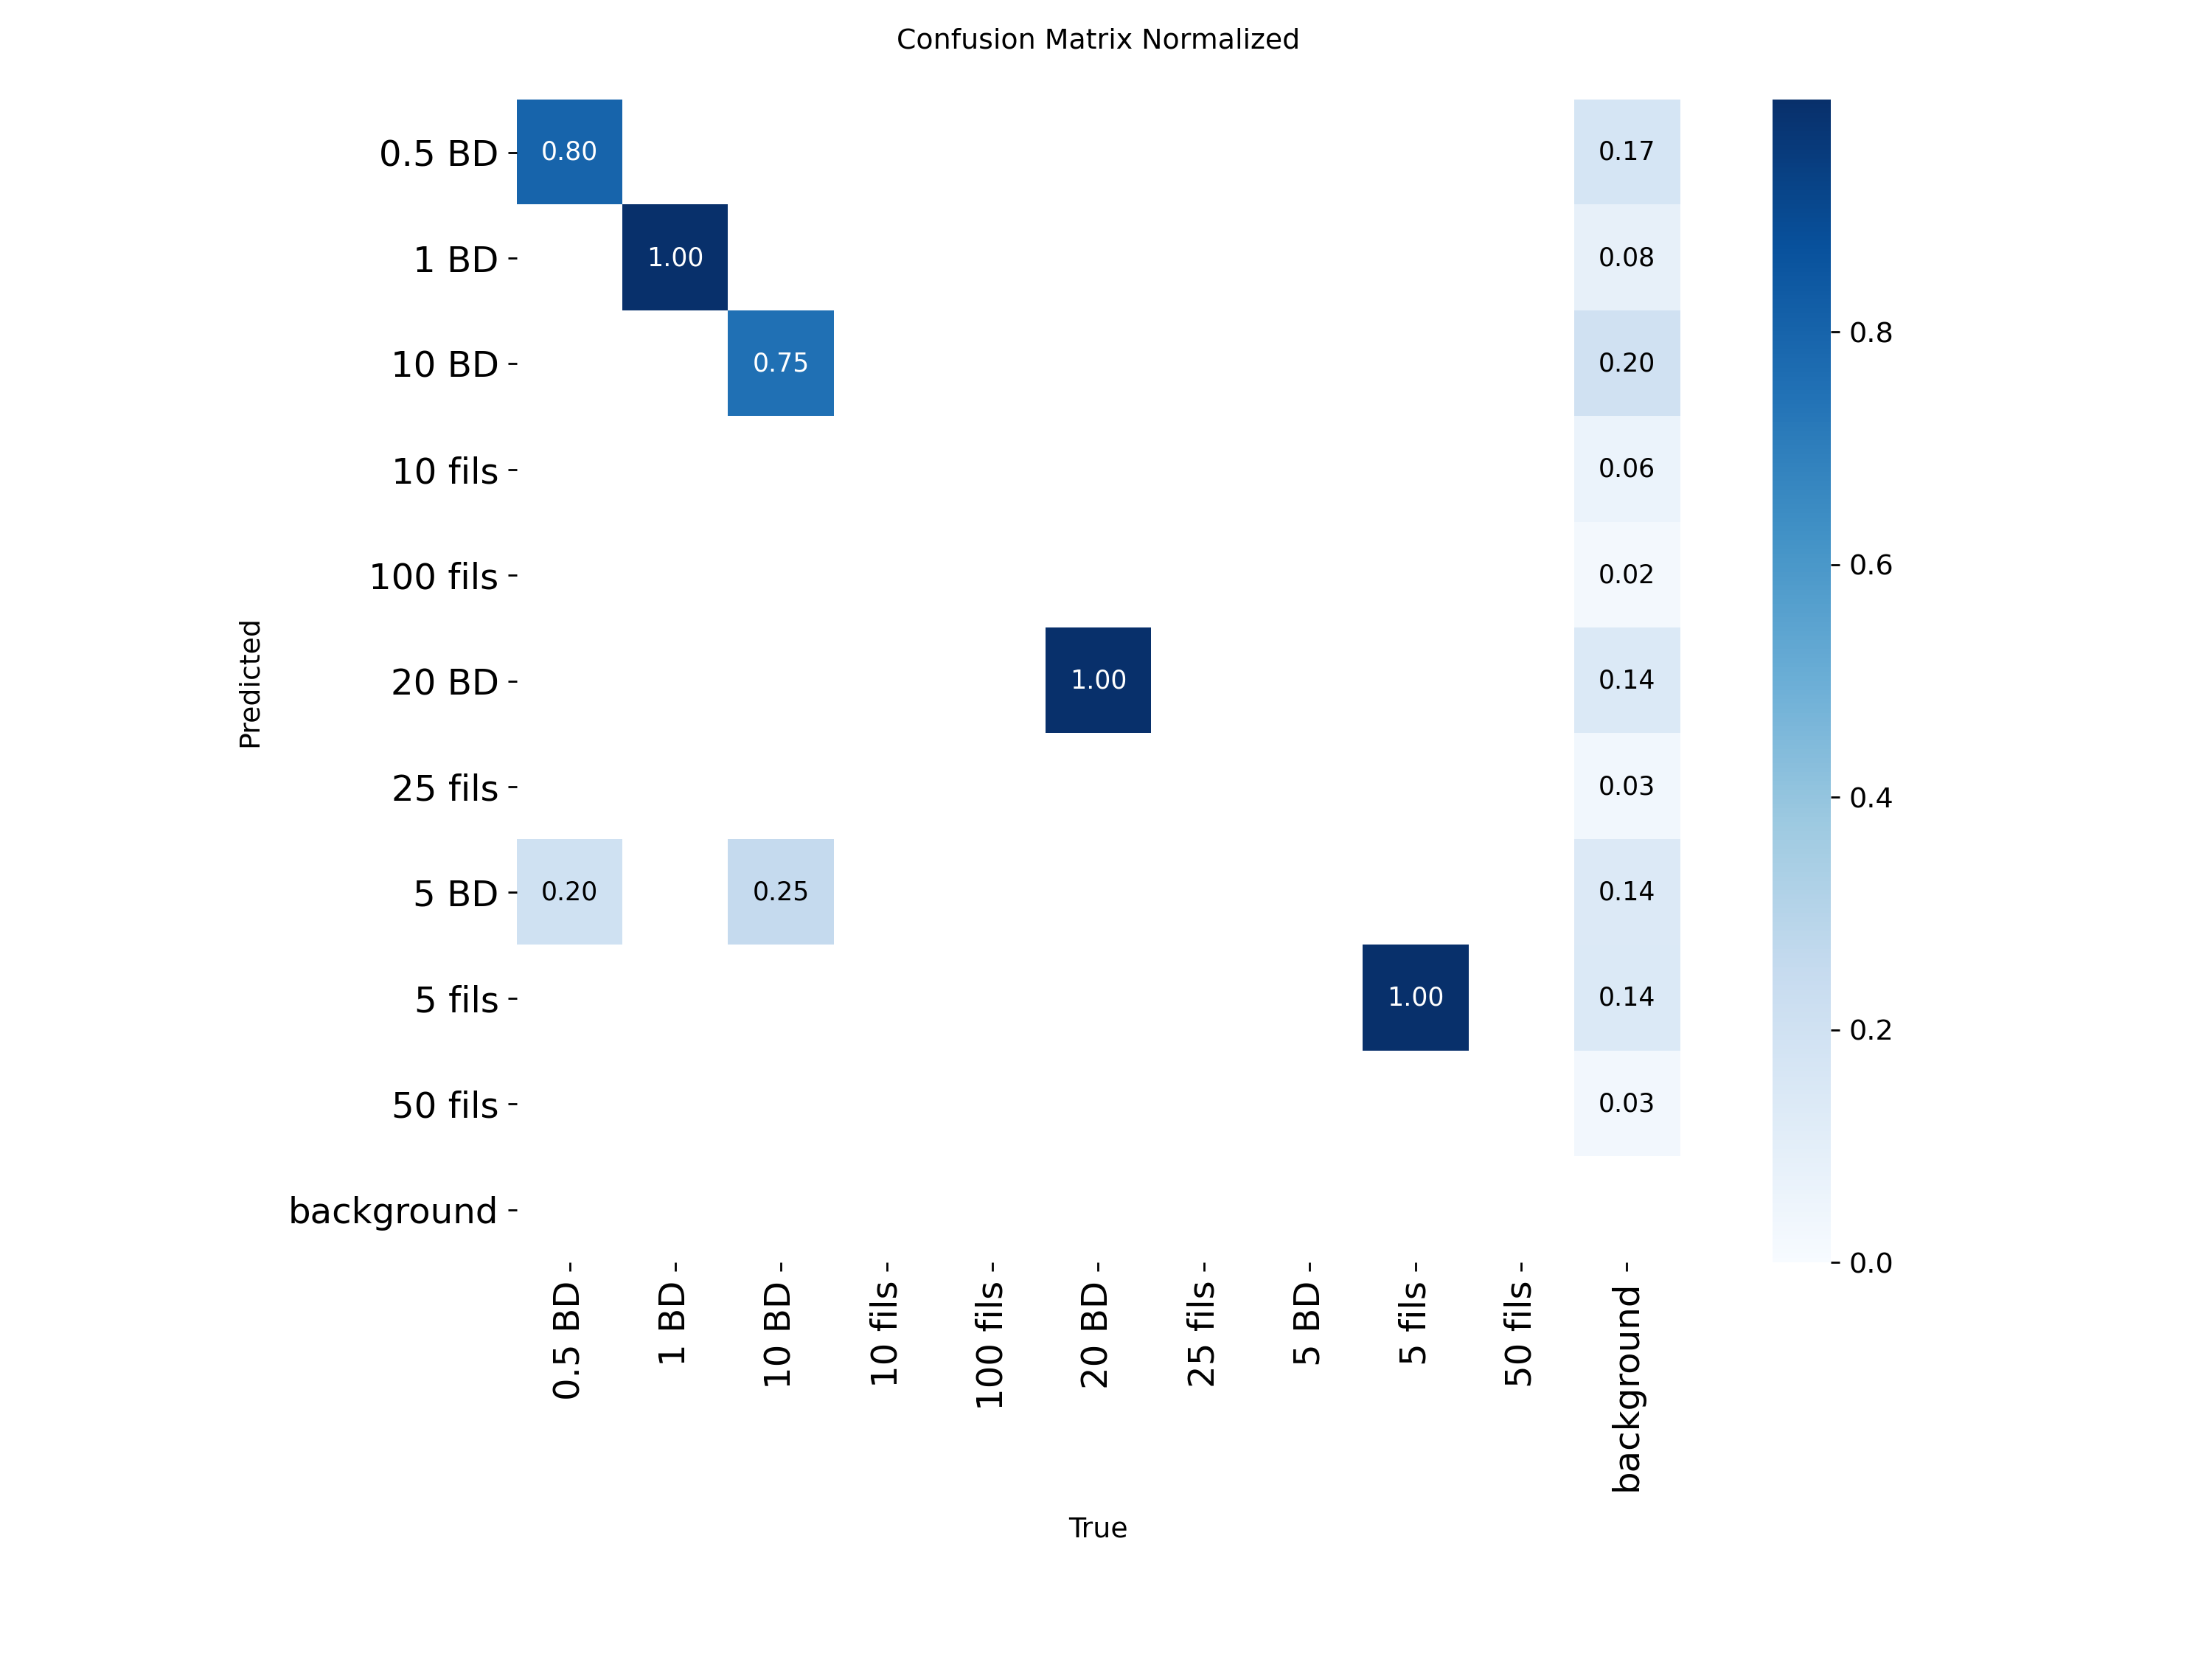

In [23]:
display(Image("runs/detect/val/confusion_matrix_normalized.png", width=700))

In [25]:
from google.colab import files
files.download("/content/runs/detect/train/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###### 1. Which currency is most confusing? `The 0.5 BD class appears to be the most challenging among the classes in the test set. It has the lowest Precision (0.725) and Recall (0.600)`

###### 2. Are similar-looking notes misclassified?`Yes, the model may confuse 10 fils and 5 fils because they look very similar. Also, 1 BD and 0.5 BD have one side that looks somewhat similar, which may make them harder for the model to distinguish.`

###### 3. Does background affect performance? `We included many different backgrounds in the dataset during training. Therefore, the background is expected to have less effect on the model's performance because it has learned from different background conditions.`

